# Stochastic gradient descent: geometry, noise, and cost

Fred J. Hickernell · MATH 565, Fall 2026

Companion to [Selected Topics: Stochastic Gradient Descent](https://fjhickernell.github.io/MATH565Fall2026/slides/05-selected-topics.html#stochastic-gradient-descent-section).

Optimization chooses decision variables $\boldsymbol\theta$ to minimize a differentiable objective $\operatorname{Loss}(\boldsymbol\theta)$. It might represent energy, cost, error, or a statistical loss. Gradient descent does not require a statistical model, observations, or a sum of component losses.

Begin with a generic one-variable loss: its slope gives a local direction, while its curvature helps us choose a distance. In several variables the Hessian describes curvature, but storing it and solving for a curvature-based step can be expensive. Gradient descent uses a simpler first-order direction; later, stochastic gradient descent makes some expensive gradients cheaper by sampling their contributions.

Why did classical optimization warn us about gradient descent on the **banana function**, while machine learning often uses stochastic gradient methods? Geometry controls the quality of a direction and step; evaluating the objective controls its cost. The lesson develops these challenges in stages before comparing methods.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH565Fall2026/blob/main/notebooks/performance/StochasticGradientDescent.ipynb)

Run All with the course `qmcpy` kernel. Change the parameter cell and rerun from the beginning. There is no downloaded dataset and no optional machine learning framework.

**Classroom route:** Parts 5–6 are the main large-data demonstration. The opening and Parts 1–4 retain optional geometry and noise analysis from the longer lecture.

- **Start:** a one-dimensional loss, slope, curvature, and step-size choice
- **Parts 1–2 — geometry:** Rosenbrock with backtracking GD and BFGS; vary conditioning separately from parameter dimension
- **Parts 3–4 — Monte Carlo gradients:** motivate an average of component losses and sampled gradients, then assess their accuracy and learning-rate choices
- **Parts 5–6 — cost:** a large-data example, equal gradient-work budgets, and measured elapsed time

Consolidates the useful gradient examples from Fall 2025. Random component indices and synthetic data use QMCPy IID sampling. All SGD batches are sampled **with replacement**.

In [1]:
from pathlib import Path
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib and QMCPy; this may take several minutes …")
    course_checkout = Path("/content/MATH565Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH565Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "-c", "submodule.qmcpy.url=https://github.com/QMCSoftware/qmcpy.git",
            "submodule", "update", "--init", "classlib", "qmcpy",
        ],
        check=True,
    )
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            str(course_checkout / "classlib"),
            str(course_checkout / "qmcpy"),
        ],
        check=True,
    )
    print("Colab setup complete.")
    print("For faster repeated work, use the local `qmcpy` environment.")

In [2]:
search_start = course_checkout if colab else Path.cwd().resolve()
course_root = next((p for p in [search_start, *search_start.parents]
                    if (p / 'course-metadata.yml').is_file()
                    and (p / 'qmcpy/qmcpy').is_dir()), None)
if course_root is None:
    raise RuntimeError('Run from the course checkout or use the Colab setup.')
for folder in ['classlib', 'qmcpy']:
    sys.path.insert(0, str(course_root / folder))

import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, rosen, rosen_der, rosen_hess
from scipy.special import expit
from IPython.display import display, Markdown
import qmcpy as qp
import classlib as cl

%matplotlib inline
cl.nbviz.init(use_tex=False)
pd.options.display.float_format = lambda x: f'{x:.6g}'
BLUE, GOLD, GREEN, RED = '#1f5a91', '#b77d17', '#398879', '#a93c42'

# Change these, then Run All. Dataset size and parameter count are independent.
SEED = 5651105
N = 16384                    # Observations, indexed 0,...,N-1
PARAMETER_DIM = 20                       # Parameters, including an intercept
REGULARIZATION = 0.02         # Applies to every parameter, including the intercept
BUDGET_PASSES = 12            # Exactly N * BUDGET_PASSES gradient contributions per run
BATCH_SIZE = 64
DIAGNOSTIC_SIZE = 1024       # s: fixed random subset for loss monitoring
LOSS_GAP_TARGET = 1e-4       # epsilon: calibrate a full-gradient check using lambda
TIMING_REPEATS = 3            # Independent SGD streams; timing ranges are not confidence intervals
GD_BANANA_STEPS = 500
NOISE_STEPS, NOISE_REPEATS = 600, 256
assert N >= 64 and PARAMETER_DIM >= 2 and REGULARIZATION > 0
assert 1 <= DIAGNOSTIC_SIZE <= N and LOSS_GAP_TARGET > 0
assert BUDGET_PASSES >= 1 and 1 <= BATCH_SIZE <= N and TIMING_REPEATS >= 1
print(f'{platform.node()}: {platform.machine()}, {platform.platform()}')
print(f'Python {platform.python_version()}, NumPy {np.__version__}, QMCPy {qp.__version__}')
print('Timings describe this machine and this implementation; rerun before presenting.')

Freds-M5-MacBook-Pro.local: arm64, macOS-27.2.1-arm64-arm-64bit-Mach-O
Python 3.13.18, NumPy 2.5.4, QMCPy 2.4
Timings describe this machine and this implementation; rerun before presenting.


## Start with one variable: slope, curvature, and a step

With one decision variable, $m=1$. For a differentiable scalar loss $\ell(\theta)$, the derivative is the tangent slope:
\begin{gather*}
\ell(\theta+\Delta)\approx\ell(\theta)+\ell'(\theta)\Delta.
\end{gather*}
A positive derivative tells us to move left; a negative derivative tells us to move right. Its magnitude describes the loss change per unit parameter change. This is local information: the loss need not keep decreasing through a long move. A zero derivative identifies a stationary point, not necessarily a minimum.

Curvature supplies another piece of information. When $\ell''(\theta)>0$, minimizing the local quadratic model gives a **Newton step**:
\begin{gather*}
\ell(\theta+\Delta)\approx\ell(\theta)+\ell'(\theta)\Delta+\tfrac12\ell''(\theta)\Delta^2,
\qquad \Delta_{\mathrm N}=-\frac{\ell'(\theta)}{\ell''(\theta)}.
\end{gather*}
This uses both slope and curvature. The model is generally only local, and a Newton step may need shortening; zero or negative curvature requires different care.

Use the generic, **nonquadratic** loss
\begin{gather*}
\ell(\theta)=\tfrac12\theta^2+\tfrac14\theta^4,\qquad
\ell'(\theta)=\theta+\theta^3,\qquad
\ell''(\theta)=1+3\theta^2.
\end{gather*}
There are no observations or statistical model. This loss is strongly convex, with global minimizer $\theta_*=0$, although its curvature changes with $\theta$. At $\theta_0=1$, its value, slope, and curvature are $0.75$, $2$, and $4$. The tangent and quadratic models are
\begin{gather*}
0.75+2\Delta,\qquad q(\Delta)=0.75+2\Delta+2\Delta^2.
\end{gather*}
The quadratic model chooses $\Delta_{\mathrm N}=-0.5$, giving $\theta_1=0.5$. It predicts loss $0.25$, while the actual loss is $0.140625$. The step helps but does not reach the true minimizer: knowing two derivatives makes a useful local model, not an exact global one.

Gradient descent instead scales the negative slope by a learning rate, $\theta_1=1-2\eta$. Compare these first moves:

| Choice | Learning rate $\eta$ | First displacement $\Delta$ | New point $\theta_1$ | Actual new loss |
|---|---:|---:|---:|---:|
| Cautious | $1/8$ | $-0.25$ | $0.75$ | $0.3603515625$ |
| Newton model at this point | $1/4$ | $-0.5$ | $0.5$ | $0.140625$ |
| Overshoot with improvement | $3/4$ | $-1.5$ | $-0.5$ | $0.140625$ |
| Too far | $9/8$ | $-2.25$ | $-1.25$ | $1.3916015625$ |

The last move increases the loss even though its initial direction is downhill. The step $\eta=1/4=1/\ell''(1)$ agrees with Newton **at the current point**; changing curvature means a fixed GD rate will not keep matching Newton at later iterates. The left picture compares the true loss and its two local models; the right compares actual candidate endpoints.

### How much scalar information makes a quadratic model?

A scalar quadratic has three coefficients. There are two useful ways to determine them:

- **Three values:** loss values at three distinct points determine an interpolating quadratic.
- **One value, one slope, and one second derivative:** $\ell(\theta_0)$, $\ell'(\theta_0)$, and $\ell''(\theta_0)$ at the same point determine its Taylor quadratic.

These constructions do not make a nonquadratic loss exactly quadratic: the interpolating model agrees at its three sample points, while the Taylor model agrees in value and its first two derivatives at the current point. Both can be imperfect away from that information.

### Cumulative challenges: the scalar stage

The example is nonquadratic but strongly convex. General scalar losses can also be nonconvex; these are separate challenges.

| Challenge | What changes? | Consequence for optimization |
|---|---|---|
| Nonquadraticity | Curvature changes as the iterate moves; a quadratic model is local | Recompute local models and safeguard the step, for example with a line search or trust region |
| Nonconvexity | A stationary point need not be a global minimizer; several local minima may exist | Try multiple starts or restarts and compare final objective values; retain the best found without claiming a global guarantee |

For a nonconvex loss, **multiple starts or restarts** are a useful practical strategy: run a local solver from several distinct starting points, evaluate its final candidates using the same full objective, and retain the best value found. Different starts can explore different attraction regions. This does not certify a global minimum, and the work includes every run plus the final objective comparisons. Changing the local solver or its curvature information can help within a run. Multiple starts do not remove nonconvexity.

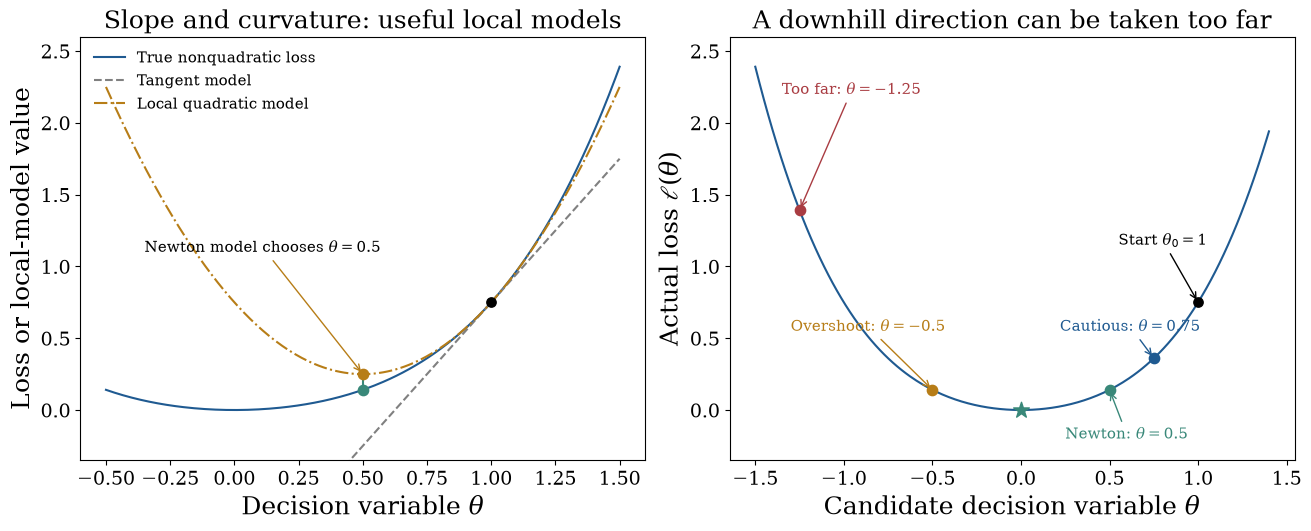

In [3]:
def scalar_loss(theta):
    theta = np.asarray(theta)
    return theta**2/2+theta**4/4

scalar_start = 1.0
scalar_value = float(scalar_loss(scalar_start))
scalar_slope = scalar_start+scalar_start**3
scalar_curvature = 1+3*scalar_start**2
scalar_newton_step = -scalar_slope/scalar_curvature

def scalar_tangent(theta):
    return scalar_value+scalar_slope*(np.asarray(theta)-scalar_start)

def scalar_quadratic_model(theta):
    return scalar_tangent(theta)+scalar_curvature*(np.asarray(theta)-scalar_start)**2/2

# Independent finite differences check the stated derivatives, not just the plotted formulas.
scalar_probe, scalar_h = 0.7, 1e-4
assert np.isclose((scalar_loss(scalar_probe+scalar_h)-scalar_loss(scalar_probe-scalar_h))
                  /(2*scalar_h), scalar_probe+scalar_probe**3, atol=1e-7)
assert np.isclose((scalar_loss(scalar_probe+scalar_h)-2*scalar_loss(scalar_probe)
                   +scalar_loss(scalar_probe-scalar_h))/scalar_h**2,
                  1+3*scalar_probe**2, atol=1e-5)
scalar_candidates = np.array([.75, .5, -.5, -1.25])
assert np.allclose(scalar_loss(scalar_candidates), [.3603515625, .140625, .140625, 1.3916015625])
assert np.isclose(scalar_start+scalar_newton_step, .5)
assert np.isclose(scalar_quadratic_model(.5), .25)
assert not np.isclose(scalar_quadratic_model(.5), scalar_loss(.5))
assert scalar_loss(.5) < scalar_value < scalar_loss(-1.25)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
local_grid = np.linspace(-.5, 1.5, 240)
axes[0].plot(local_grid, scalar_loss(local_grid), color=BLUE, label='True nonquadratic loss')
axes[0].plot(local_grid, scalar_tangent(local_grid), '--', color='0.5', label='Tangent model')
axes[0].plot(local_grid, scalar_quadratic_model(local_grid), '-.', color=GOLD,
             label='Local quadratic model')
axes[0].scatter([scalar_start], [scalar_value], color='black', s=45, zorder=5)
axes[0].scatter([.5], [scalar_quadratic_model(.5)], color=GOLD, s=55, zorder=5)
axes[0].scatter([.5], [scalar_loss(.5)], color=GREEN, s=55, zorder=5)
axes[0].plot([.5,.5], [scalar_loss(.5), scalar_quadratic_model(.5)], color=GREEN, linewidth=1.5)
axes[0].annotate(r'Newton model chooses $\theta=0.5$', xy=(.5, .25), xytext=(-.35, 1.1),
                 fontsize=11, arrowprops=dict(arrowstyle='->', color=GOLD))
axes[0].set(xlabel=r'Decision variable $\theta$', ylabel='Loss or local-model value',
            title='Slope and curvature: useful local models', ylim=(-.35, 2.6))
axes[0].legend(frameon=False, fontsize=11, loc='upper left')

wide_grid = np.linspace(-1.5, 1.4, 240)
axes[1].plot(wide_grid, scalar_loss(wide_grid), color=BLUE, linewidth=1.5)
axes[1].scatter([0], [0], marker='*', s=140, color=GREEN, zorder=4)
axes[1].scatter([scalar_start], [scalar_value], color='black', s=45, zorder=5)
axes[1].annotate(r'Start $\theta_0=1$', xy=(scalar_start,scalar_value), xytext=(.55,1.15),
                 fontsize=11, arrowprops=dict(arrowstyle='->', color='black'))
for theta, color, label, text_position in [
    (.75, BLUE, r'Cautious: $\theta=0.75$', (.22, .55)),
    (.5, GREEN, r'Newton: $\theta=0.5$', (.25, -.2)),
    (-.5, GOLD, r'Overshoot: $\theta=-0.5$', (-1.3, .55)),
    (-1.25, RED, r'Too far: $\theta=-1.25$', (-1.35, 2.2)),
]:
    axes[1].scatter([theta], [scalar_loss(theta)], color=color, s=55, zorder=4)
    axes[1].annotate(label, xy=(theta, scalar_loss(theta)), xytext=text_position,
                     fontsize=11, color=color, arrowprops=dict(arrowstyle='->', color=color))
axes[1].set(xlabel=r'Candidate decision variable $\theta$', ylabel=r'Actual loss $\ell(\theta)$',
            title='A downhill direction can be taken too far', ylim=(-.35, 2.6))
plt.show()

### What changes with more parameters or a more complicated loss?

For $\boldsymbol\theta\in\mathbb R^m$, the gradient collects $m$ partial derivatives. The directional derivative in direction $\boldsymbol v$ is $\nabla F(\boldsymbol\theta)^\top\boldsymbol v$. Among Euclidean unit directions, $-\nabla F/\|\nabla F\|$ gives the steepest local decrease when the gradient is nonzero. A gradient is still local information; its size and direction do not determine a safe long step.

The **Hessian** $H(\boldsymbol\theta)$ is the matrix of second partial derivatives. It describes the next term in a smooth local model,
\begin{gather*}
F(\boldsymbol\theta+\boldsymbol\Delta)\approx F(\boldsymbol\theta)
+\nabla F(\boldsymbol\theta)^\top\boldsymbol\Delta
+\tfrac12\boldsymbol\Delta^\top H(\boldsymbol\theta)\boldsymbol\Delta.
\end{gather*}
For positive-definite curvature, its eigenvalues describe steep and shallow orthogonal directions. A general quadratic has $1+m+m(m+1)/2$ coefficients: one constant, $m$ first-order terms, and $m(m+1)/2$ distinct symmetric curvature entries. Estimating unrestricted curvature therefore needs information about mixed directions as well as separate coordinate slopes. A Newton direction solves $H(\boldsymbol\theta)\boldsymbol\Delta=-\nabla F(\boldsymbol\theta)$, the multidimensional counterpart of dividing by scalar curvature. A dense $m\times m$ Hessian needs $O(m^2)$ storage and a naive dense solve needs $O(m^3)$ arithmetic. Those costs motivate using a first-order direction represented by an $m$-vector. Computing that gradient still depends on the objective's evaluation cost and structure; it is **not universally $O(m)$**. Hessian-vector products, sparse structure, and limited-memory methods offer other choices.

These dense-Hessian costs grow with the **number of decision variables** $m$. When $m$ is small, Newton or a quasi-Newton method can still be a practical and effective choice; the existence of a first-order direction does not make it the best choice for every loss.

GD's single learning rate must work across steep and shallow directions. If the Hessian varies with the point, the local quadratic picture changes as we move.

**Nonquadraticity** means being nonquadratic; “changing curvature” is often easier to picture. It is different from nonconvexity: a nonquadratic objective can remain convex, as the opening scalar loss does. The conditioning ratio used below describes positive-definite curvature, rather than every indefinite Hessian encountered in a nonconvex problem.

The next two parts examine geometry. Part 3 then introduces a separate cost: forming a gradient that sums contributions from many observations.

## 1. The banana function is still difficult

The two-dimensional Rosenbrock objective is
\begin{gather*}
R(\boldsymbol\theta)=(1-\theta_1)^2+100(\theta_2-\theta_1^2)^2,
\qquad \boldsymbol\theta_*=(1,1)^\top,\\
\nabla R(\boldsymbol\theta)=
\begin{bmatrix}2(\theta_1-1)-400\theta_1(\theta_2-\theta_1^2)\\200(\theta_2-\theta_1^2)\end{bmatrix}.
\end{gather*}

A narrow curved valley makes the steepest local direction a poor guide to a long step. Compare two methods:

- **GD + backtracking** moves in the negative-gradient direction. Armijo backtracking starts with step size 1, tries the proposed endpoint, and halves the step size until the loss decreases sufficiently. It adjusts the step length, but not the direction; slow progress can persist despite this adaptive step size.
- **BFGS** builds an inverse-Hessian approximation from successive steps and gradients to adjust both the direction and scale of a step. It uses a line search but does not evaluate the exact Hessian.

The green star marks the minimizer $(1,1)$. Lines connect successive accepted iterates: the long blue segment is one GD update, not a continuous downhill trajectory. Backtracking checks its endpoint, so the connecting line can cross higher contours even though the endpoint lowers the loss. A separate close-up shows the much smaller later GD steps moving back and forth across the valley while making slow progress toward the minimizer.

The plots count **accepted updates**, which are not equal work. The table separately counts objective and gradient evaluations, including GD's rejected line-search trials. Rosenbrock is a deterministic geometry example; this experiment compares local optimization methods.

Hessian eigenvalues at the minimizer: [3.99360767e-01 1.00160064e+03]
Local condition number: 2508.0


,Method,Accepted updates,Objective evaluations,Gradient evaluations,Final objective
0,GD + backtracking,500,4905,500,0.00191572
1,BFGS,34,41,41,4.35095e-25


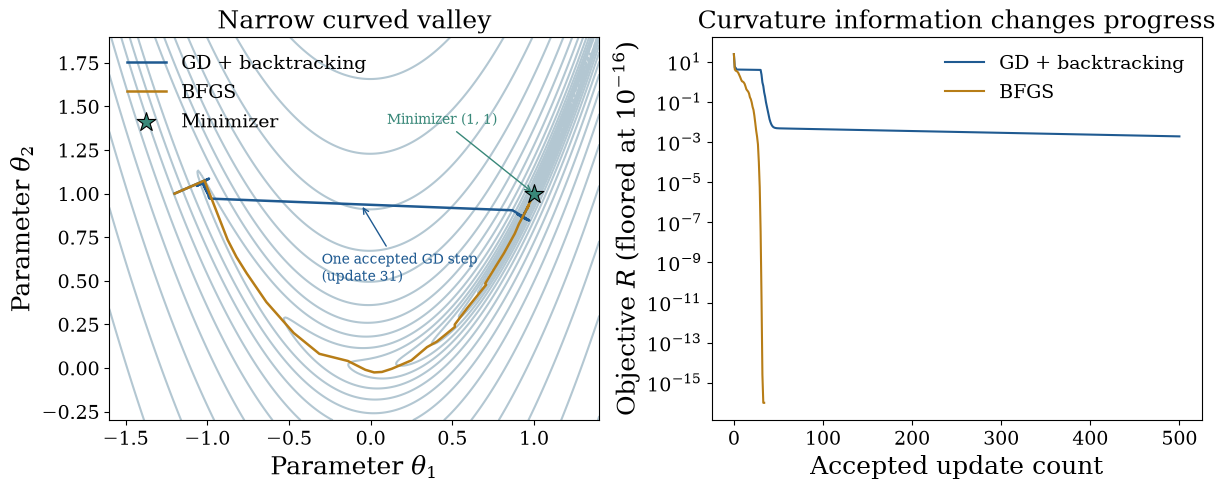

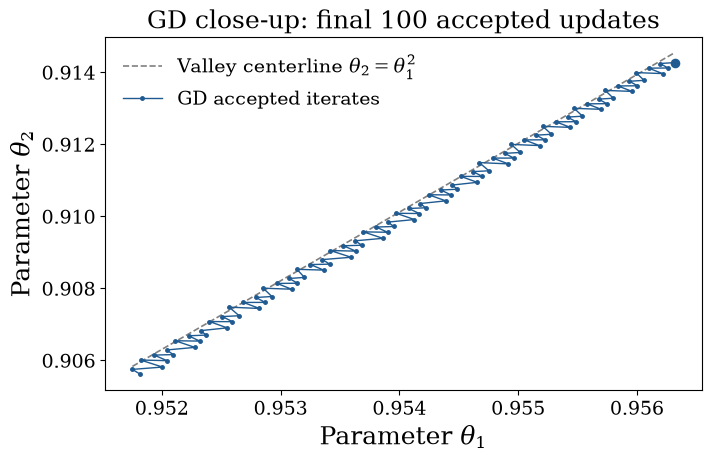

In [4]:
def banana_gd(start, steps):
    theta = np.array(start, dtype=float)
    path = [theta.copy()]
    values = [rosen(theta)]
    nfun, ngrad = 1, 0
    for _ in range(steps):
        g = rosen_der(theta)
        ngrad += 1
        eta = 1.0
        candidate_value = rosen(theta - eta*g)
        nfun += 1
        while candidate_value > values[-1] - 1e-4*eta*(g@g):
            eta *= 0.5
            candidate_value = rosen(theta - eta*g)
            nfun += 1
        theta -= eta*g
        path.append(theta.copy())
        values.append(candidate_value)
    return np.array(path), np.array(values), nfun, ngrad

banana_start = np.array([-1.2, 1.0])
gd_path, gd_values, gd_nfun, gd_ngrad = banana_gd(banana_start, GD_BANANA_STEPS)
bfgs_path = [banana_start.copy()]
bfgs = minimize(rosen, banana_start, jac=rosen_der, method='BFGS',
                callback=lambda x: bfgs_path.append(x.copy()), options={'gtol': 1e-8})
bfgs_path = np.array(bfgs_path)
assert bfgs.success, bfgs.message
assert np.all(np.diff(gd_values) <= 1e-12)
assert np.linalg.norm(bfgs.x - 1) < 1e-6
hessian_eigenvalues = np.linalg.eigvalsh(rosen_hess(np.ones(2)))
print('Hessian eigenvalues at the minimizer:', hessian_eigenvalues)
print(f'Local condition number: {hessian_eigenvalues[-1]/hessian_eigenvalues[0]:.1f}')
display(pd.DataFrame([
    ['GD + backtracking', len(gd_path)-1, gd_nfun, gd_ngrad, gd_values[-1]],
    ['BFGS', bfgs.nit, bfgs.nfev, bfgs.njev, bfgs.fun],
], columns=['Method', 'Accepted updates', 'Objective evaluations', 'Gradient evaluations', 'Final objective']))

xx, yy = np.meshgrid(np.linspace(-1.6, 1.4, 260), np.linspace(-0.3, 1.9, 260))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].contour(xx, yy, (1-xx)**2 + 100*(yy-xx**2)**2,
                levels=np.geomspace(0.02, 500, 18), colors='#b3c7d2')
for path, color, label in [(gd_path, BLUE, 'GD + backtracking'), (bfgs_path, GOLD, 'BFGS')]:
    axes[0].plot(*path.T, color=color, linewidth=1.8, label=label)
    axes[1].semilogy(np.arange(len(path)), np.maximum([rosen(x) for x in path], 1e-16),
                     color=color, label=label)
# Draw the minimizer above both paths so the converged BFGS path cannot hide it.
axes[0].scatter([1], [1], marker='*', s=200, color=GREEN, edgecolors='black',
                linewidths=0.8, zorder=6, label='Minimizer')
axes[0].annotate('Minimizer (1, 1)', xy=(1, 1), xytext=(0.1, 1.4),
                 color=GREEN, arrowprops=dict(arrowstyle='->', color=GREEN), zorder=7)
jump_index = 1 + np.argmax(np.linalg.norm(np.diff(gd_path, axis=0), axis=1))
jump_midpoint = (gd_path[jump_index-1] + gd_path[jump_index]) / 2
axes[0].annotate(f'One accepted GD step\n(update {jump_index})', xy=jump_midpoint,
                 xytext=(-0.3, 0.5), color=BLUE,
                 arrowprops=dict(arrowstyle='->', color=BLUE))
axes[0].set(xlabel=r'Parameter $\theta_1$', ylabel=r'Parameter $\theta_2$', title='Narrow curved valley')
axes[1].set(xlabel='Accepted update count', ylabel=r'Objective $R$ (floored at $10^{-16}$)',
            title='Curvature information changes progress')
axes[0].legend(loc='upper left', frameon=False)
axes[1].legend(frameon=False)
plt.show()

# Every dot is an accepted iterate; zooming reveals the small late zigzags.
recent_gd = gd_path[-101:]
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
zoom_x = np.linspace(recent_gd[:, 0].min(), recent_gd[:, 0].max(), 200)
ax.plot(zoom_x, zoom_x**2, '--', color='0.5', linewidth=1.2,
        label=r'Valley centerline $\theta_2=\theta_1^2$')
ax.plot(*recent_gd.T, '.-', color=BLUE, markersize=5, linewidth=1,
        label='GD accepted iterates')
ax.scatter(*recent_gd[-1], s=35, color=BLUE, zorder=4)
ax.set(xlabel=r'Parameter $\theta_1$', ylabel=r'Parameter $\theta_2$',
       title=f'GD close-up: final {len(recent_gd)-1} accepted updates')
ax.ticklabel_format(style='plain', useOffset=False)
ax.legend(loc='upper left', frameon=False)
plt.show()

## 2. Conditioning and dimension are different

This section illustrates **separate quadratic models with a constant Hessian**. The $\kappa=2508$ case matches the rounded condition number of Rosenbrock’s Hessian at its minimizer; its worst-case iteration counts are not predictions for the Rosenbrock run in Section 1, whose Hessian varies along the path.

For the symmetric positive-definite quadratic $F(\boldsymbol\theta)=\boldsymbol\theta^\top A\boldsymbol\theta/2$, each eigenvector component is multiplied by $1-\eta\lambda_j(A)$ at an update. The best worst-case constant learning rate is
\begin{gather*}
\eta_* = \frac{2}{\lambda_{\max}+\lambda_{\min}},\qquad
q=\max_j|1-\eta_*\lambda_j|=\frac{\kappa-1}{\kappa+1},\qquad
\kappa(H)=\lambda_{\max}(H)/\lambda_{\min}(H),\qquad H=A.
\end{gather*}

**We want a small contraction factor $q$.** It bounds the fraction of distance to the minimizer **remaining after one update**. A factor near 1 leaves nearly all the error: for $\kappa=2508$, $q\approx0.9992$, so the guaranteed reduction per update is only about $0.08\%$. Smaller $q$ means faster guaranteed progress.

The table computes this worst-case Euclidean error contraction at the displayed best constant step size. Adding coordinates with the same extreme eigenvalues does not change $q$. For a million-dimensional identity quadratic, every Hessian eigenvalue is 1: $\kappa=1$, $\eta_*=1$, and $q=0$. One GD update removes all parameter error, although reading and updating its million coordinates still costs work. A two-dimensional ill-conditioned quadratic can take many updates. A good preconditioner changes the effective curvature; sampling a gradient does not do that by itself.

In [5]:
conditioning = []
for dimension in [2, 20, 1_000_000]:
    for kappa in [1, 100, 2508]:
        q = (kappa-1)/(kappa+1)
        required = 1 if q == 0 else int(np.ceil(np.log(1e-3)/np.log(q)))
        conditioning.append([dimension, kappa, q, required])
conditioning_table = pd.DataFrame(conditioning, columns=['Dimension m', 'Condition number', 'Error fraction remaining',
                                                         'Updates for 1000-fold error reduction'])
conditioning_table['Condition number'] = conditioning_table['Condition number'].map(
    lambda kappa: '2508 (Rosenbrock actual at minimizer)' if kappa == 2508 else str(kappa))
display(conditioning_table)
# Independent check of the eigenvalue contraction formula.
A_diag = np.diag([1.0, 100.0])
eta_best = 2 / 101
assert np.isclose(np.linalg.norm(np.eye(2)-eta_best*A_diag, 2), 99/101)

,Dimension m,Condition number,Error fraction remaining,Updates for 1000-fold error reduction
0,2,1,0,1
1,2,100,0.980198,346
2,2,2508 (Rosenbrock actual at minimizer),0.999203,8663
3,20,1,0,1
4,20,100,0.980198,346
5,20,2508 (Rosenbrock actual at minimizer),0.999203,8663
6,1000000,1,0,1
7,1000000,100,0.980198,346
8,1000000,2508 (Rosenbrock actual at minimizer),0.999203,8663


### Cumulative challenges: before expensive full gradients

We have met four challenges so far. The next part introduces a separate cost for a full gradient that averages many contributions.

| Challenge | What changes? | Consequence for optimization |
|---|---|---|
| Nonquadraticity | Curvature changes as the iterate moves; a quadratic model is local | Recompute local models and safeguard the step, for example with a line search or trust region |
| Nonconvexity | A stationary point need not be a global minimizer; several local minima may exist | Try multiple starts or restarts and compare final objective values; retain the best found without claiming a global guarantee |
| Full dense Hessian cost | Storing and solving with unrestricted curvature costs $O(m^2)$ storage and $O(m^3)$ dense-solve work | Consider first-order directions, L-BFGS, structure, or Hessian-vector methods; full Newton can remain useful for small $m$ |
| Conditioning | One learning rate must accommodate steep and shallow directions | Scale variables, precondition, or use curvature information; choose the step with those different scales in mind |

## 3. A gradient really can be a Monte Carlo estimate

### When the loss averages contributions: nonlinear regression

The general loss need not involve data. A common special case does: observations $(\boldsymbol x_i,y_i)$ each contribute a prediction error. To make the prediction genuinely nonlinear in the $m$ parameters, use an exponential response,
\begin{gather*}
\widehat y_i(\boldsymbol\theta)=\exp(\boldsymbol x_i^\top\boldsymbol\theta),\qquad
\operatorname{loss}_i(\boldsymbol\theta)=\tfrac12[\widehat y_i(\boldsymbol\theta)-y_i]^2,\\
F(\boldsymbol\theta)=\frac1N\sum_{i=0}^{N-1}\operatorname{loss}_i(\boldsymbol\theta),\qquad
\nabla\operatorname{loss}_i(\boldsymbol\theta)
=[\widehat y_i(\boldsymbol\theta)-y_i]\widehat y_i(\boldsymbol\theta)\boldsymbol x_i.
\end{gather*}
The chain rule gives the last expression. We can still **evaluate** predictions and gradients using vectorized matrix operations, but their dependence on $\boldsymbol\theta$ means there is no one-time linear normal-equation solve for this objective. Taking logarithms of responses would define a different regression loss rather than solve this squared-error problem.

A **mini-batch gradient** averages $b$ sampled observation gradients, all evaluated at the **same current** $\boldsymbol\theta$. Form that average first, then make one parameter update.

For this dense exponential predictor, evaluating one observation's loss and gradient costs $O(m)$ arithmetic: an inner product, a scalar exponential, and a scaled feature vector. Dense linear and logistic predictors also have $O(m)$ per-observation costs; a more complicated nonlinear model can have a different evaluation cost. A direct full loss and gradient use $O(Nm)$; a batch of $b$ sampled observation contributions uses $O(bm)$, plus the parameter update. The benefit comes from sampling the **observation contributions**, not from making every possible gradient a universal $O(m)$ calculation. An unbiased sampled gradient estimates the $N$-term average, with no additional division by $N$. Streaming or expectation objectives admit a related sampling interpretation.

### Large data size and large parameter dimension are separate challenges

$N$ counts **observations** and $m$ counts **model parameters**; they are independent controls. Large $N$ motivates sampling observation contributions. Large $m$ makes an unrestricted dense Hessian and its solve expensive. Neither fact alone selects the best optimizer.

| Operation in a dense observation model | Arithmetic work | Derivative storage, excluding the data |
|---|---:|---:|
| Full loss and gradient | $O(Nm)$ | $O(m)$ |
| Accumulate a full Hessian from observation contributions | $O(Nm^2)$ | $O(m^2)$ |
| Solve a dense Newton system after derivatives are formed | $O(m^3)$ | $O(m^2)$ |

For **$m=2$**, the gradient has two entries, the symmetric Hessian has only three independent entries, and the Newton system is a tiny $2\times2$ solve. At fixed $m=2$, forming either full derivative is $O(N)$, even if $N$ is enormous. Gradient and Hessian contributions can be accumulated in the **same pass** through the observations. That pass may be expensive, but a curvature-informed step may require fewer passes than first-order updates. Newton remains worth considering when $m$ is small.

**Linear least squares is an important contrast:** its curvature is constant, permitting additional reuse. Let the rows of $X$ be $\boldsymbol x_i^\top$ and let $\boldsymbol y$ collect the responses. Then
\begin{gather*}
F(\boldsymbol\theta)=\frac{\|X\boldsymbol\theta-\boldsymbol y\|^2}{2N},\qquad
\nabla F(\boldsymbol\theta)=\frac{(X^\top X)\boldsymbol\theta-X^\top\boldsymbol y}{N},
\qquad H=\frac{X^\top X}{N}.
\end{gather*}
Precompute $X^\top X$ and $X^\top\boldsymbol y$ once: later gradients require $O(m^2)$ work with **no new $N$-row pass**, and the Hessian stays constant. If $X$ has full column rank, the Newton system is positive definite and its exact quadratic step reaches the least-squares minimizer. These identities explain reuse; a QR or SVD solve may be preferable numerically to solving normal equations. For the exponential nonlinear predictor above, or the logistic model in Part 5, the Hessian changes with the iterate and the same precomputation does not supply the current Hessian.

Choosing full Newton, a quasi-Newton method, GD, or SGD therefore depends on curvature, derivative reuse, accuracy, and actual cost. Sampling curvature or using Hessian-vector products can offer further compromises; this notebook adds no such algorithm or benchmark.

### Cumulative challenges: add the full-gradient data pass

The new issue is the number $N$ of loss contributions. Sampling is one response to that cost; it does not remove the four geometric and curvature-cost challenges already listed.

| Challenge | What changes? | Consequence for optimization |
|---|---|---|
| Nonquadraticity | Curvature changes as the iterate moves; a quadratic model is local | Recompute local models and safeguard the step, for example with a line search or trust region |
| Nonconvexity | A stationary point need not be a global minimizer; several local minima may exist | Try multiple starts or restarts and compare final objective values; retain the best found without claiming a global guarantee |
| Full dense Hessian cost | Storing and solving with unrestricted curvature costs $O(m^2)$ storage and $O(m^3)$ dense-solve work | Consider first-order directions, L-BFGS, structure, or Hessian-vector methods; full Newton can remain useful for small $m$ |
| Conditioning | One learning rate must accommodate steep and shallow directions | Scale variables, precondition, or use curvature information; choose the step with those different scales in mind |
| Full-gradient / data-pass cost | A direct dense gradient can cost $O(Nm)$ per data pass, even when $m$ is small | Reuse derivative structure when available, or sample $b$ observation contributions to reduce work per update; Newton remains possible for small $m$ |

### From one observation to a mini-batch

At iteration $k$, the data and loss formula are available, and $\boldsymbol\theta_k$ is the **known vector stored by the algorithm**. The desired minimizer $\boldsymbol\theta_*$ is generally unknown and is not needed for an update. The full gradient is computable but may be costly. Choose $b,\eta_k$, draw a batch, and compute $\boldsymbol G_k$; its realized value is known.

Start with **single-observation SGD**. At the current iterate $\boldsymbol\theta_k$, draw one fresh index $I_k$ uniformly from $\{0,\ldots,N-1\}$, independently of previous draws. Define its gradient estimate and make one update:
\begin{gather*}
\boldsymbol G_k=\nabla\operatorname{loss}_{I_k}(\boldsymbol\theta_k),\qquad
\boldsymbol\theta_{k+1}=\boldsymbol\theta_k-\eta_k\boldsymbol G_k.
\end{gather*}
For **mini-batch SGD**, generalize that definition: draw $b$ fresh IID indices $I_{kj}$ with replacement, evaluate every component gradient at the same $\boldsymbol\theta_k$, and average before the update:
\begin{gather*}
\boldsymbol G_k=\frac1b\sum_{j=0}^{b-1}\nabla\operatorname{loss}_{I_{kj}}(\boldsymbol\theta_k),\qquad
\boldsymbol\theta_{k+1}=\boldsymbol\theta_k-\eta_k\boldsymbol G_k.
\end{gather*}
The case $b=1$ recovers single-observation SGD. Write $\boldsymbol g_k=\nabla\operatorname{Loss}(\boldsymbol\theta_k)$ for the full gradient and $\boldsymbol G_k$ for the sampled estimate. We differentiate the selected loss terms, average their gradients, and use that average for the cheap update. The history $\mathcal F_k$ includes previous draws and the current iterate; choose the positive learning rate $\eta_k$ before drawing the current update batch. Next identify the random-input dimension of this already defined gradient estimate, then examine its sampling error.

### A small finite-sum model with exact references

Use the four sign choices $\boldsymbol a_i=(\pm1/4,\pm1/4)^\top$ and
\begin{gather*}
\operatorname{loss}_i(\boldsymbol\theta)=\tfrac12(\boldsymbol\theta-\boldsymbol a_i)^\top A(\boldsymbol\theta-\boldsymbol a_i),
\qquad A=\begin{bmatrix}3&0.9\\0.9&1.2\end{bmatrix},\\
\nabla\operatorname{loss}_i(\boldsymbol\theta)=A(\boldsymbol\theta-\boldsymbol a_i),\qquad
\nabla\operatorname{Loss}(\boldsymbol\theta)=A\boldsymbol\theta.
\end{gather*}

For this **fixed four-component dataset**, $m=2$ parameters and $N=4$ components. The actual sampler uses one scalar uniform $U\in[0,1)$ and $I=\lfloor4U\rfloor$. For this **single-component draw**, $d=1$, even though its gradient output has two coordinates. With the iterate fixed,
\begin{gather*}
\widetilde{\boldsymbol g}_{\boldsymbol\theta}(u)
=\nabla\operatorname{loss}_{\lfloor4u\rfloor}(\boldsymbol\theta),\qquad
\nabla\operatorname{Loss}(\boldsymbol\theta)=\int_0^1
\widetilde{\boldsymbol g}_{\boldsymbol\theta}(u)\,\mathrm du.
\end{gather*}

One **mini-batch-gradient draw** requires the random index vector $(I_0,\ldots,I_{b-1})$, generated from a uniform vector in $[0,1]^b$. Thus **$d=b$ for one mini-batch-gradient draw**; single-observation SGD has $b=1$ and $d=1$. Evaluate all $b$ component gradients at the same current iterate, average them, and make one parameter update. The resulting gradient has $m$ coordinates, while $N$ is the dataset size. The code generates a scalar IID stream and groups consecutive indices into these length-$b$ vectors; the sampling law and computed results are unchanged.

### Gradient noise from sampling

A fresh uniform index $I_k\in\{0,1,2,3\}$ gives a **conditionally unbiased gradient** at the current iterate, given its previous history $\mathcal F_k$. It does not make the iterate an unbiased minimizer estimate and does not ensure a decrease at every step. At the minimizer, the four individual gradients are nonzero.

**Gradient noise** is the difference $\boldsymbol G_k-\nabla F(\boldsymbol\theta_k)$ caused by the sampled indices. At a fixed iterate $\boldsymbol\theta$, define the single-component variance and the IID batch-gradient mean squared error:
\begin{gather*}
\sigma^2=\frac1N\sum_{i=0}^{N-1}\|\nabla\operatorname{loss}_i(\boldsymbol\theta)-\nabla F(\boldsymbol\theta)\|^2,
\qquad
\mathbb E\|\boldsymbol G-\nabla F(\boldsymbol\theta)\|^2=\frac{\sigma^2}{b}.
\end{gather*}

The path comparison has $m=2$, $N=4$ and $b=1$: 45 GD moves and 180 SGD moves each cost 180 component-gradient evaluations. GD uses constant $\eta=0.18$; SGD uses decreasing $\eta_k=0.12/\sqrt{1+k/8}$. The implementations use the same component losses and schedules as the slide; the notebook retains QMCPy IID sampling, so the particular sampled path can differ. The shared quadratic structure also permits simplifying the full gradient to $A\boldsymbol\theta$; we enumerate four components here to illustrate accounting, not to claim a timing advantage for this reducible toy.

The contours show excess average loss $\operatorname{Loss}(\boldsymbol\theta)-\operatorname{Loss}(\boldsymbol0)=\boldsymbol\theta^\top A\boldsymbol\theta/2$. This small picture illustrates noise, not a timing advantage from a large dataset.

The first variance table below is a controlled check: it enumerates all four component gradients to find the exact full gradient and exact component variance $\sigma^2$, then measures gradient MSE over 4,096 independent batches. That known-reference calculation is different from estimating unknown noise from one batch; the following diagnostic makes that distinction explicit.

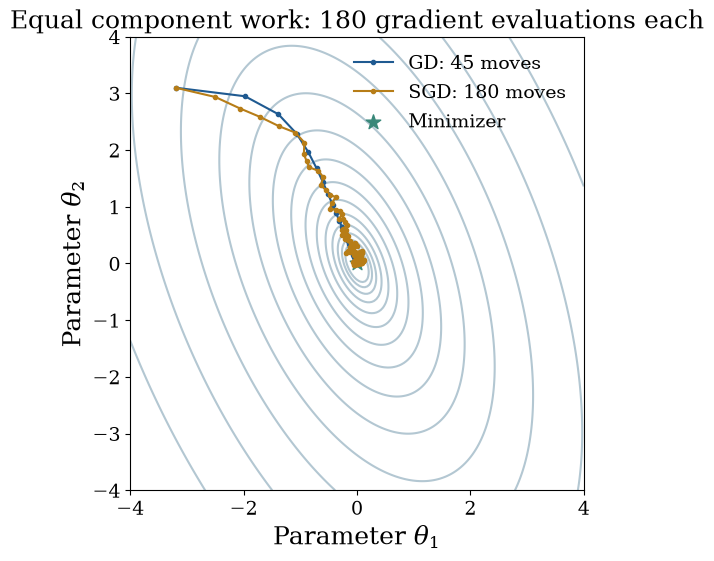

,Batch size b,Exact mean squared gradient error,Measured mean squared gradient error
0,1,0.75375,0.760441
1,4,0.188437,0.194446
2,16,0.0471094,0.0469189
3,64,0.0117773,0.0117042


In [6]:
A = np.array([[3.0, 0.9], [0.9, 1.2]])
centers = np.array([[.25, .25], [.25, -.25], [-.25, .25], [-.25, -.25]])
probe = np.array([.7, -.4])
components = (probe-centers) @ A.T
assert np.allclose(components.mean(axis=0), A@probe)

# N=4 components, m=2 parameters, b=1 for SGD: 180 component gradients each.
gd_moves = 45
component_budget = gd_moves*len(centers)
sgd_moves = component_budget
indices = (len(centers)*qp.IIDStdUniform(1, seed=56505).gen_samples(sgd_moves).ravel()).astype(int)
gd, sgd = [np.array([-3.2, 3.1])], [np.array([-3.2, 3.1])]
for _ in range(gd_moves):
    g_k = ((gd[-1]-centers) @ A.T).mean(axis=0)
    gd.append(gd[-1] - .18*g_k)
for k, i in enumerate(indices):
    G_k = A@(sgd[-1]-centers[i])
    sgd.append(sgd[-1] - .12/np.sqrt(1+k/8)*G_k)
assert gd_moves*len(centers) == sgd_moves == 180
gd, sgd = np.array(gd), np.array(sgd)
xx, yy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-4, 4, 200))
zz = .5*(A[0,0]*xx**2 + 2*A[0,1]*xx*yy + A[1,1]*yy**2)
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
ax.contour(xx, yy, zz, levels=np.geomspace(.05, 30, 14), colors='#b3c7d2')
ax.plot(*gd.T, '-o', markersize=3, color=BLUE, label='GD: 45 moves')
ax.plot(*sgd.T, '-o', markersize=3, color=GOLD, label='SGD: 180 moves')
ax.scatter([0], [0], marker='*', s=120, color=GREEN, label='Minimizer')
ax.set(xlabel=r'Parameter $\theta_1$', ylabel=r'Parameter $\theta_2$', aspect='equal')
ax.set_title('Equal component work: 180 gradient evaluations each')
ax.legend(frameon=False)
plt.show()

# The variance identity is exact for independent draws with replacement.
sigma2 = np.mean(np.sum((components-components.mean(axis=0))**2, axis=1))
variance_rows=[]
for b in [1, 4, 16, 64]:
    u = qp.IIDStdUniform(1, seed=SEED+b).gen_samples(4096*b).ravel()
    batch_gradients = components[(4*u).astype(int)].reshape(4096, b, 2).mean(axis=1)
    measured = np.mean(np.sum((batch_gradients-A@probe)**2, axis=1))
    variance_rows.append([b, sigma2/b, measured])
display(pd.DataFrame(variance_rows, columns=['Batch size b', 'Exact mean squared gradient error',
                                            'Measured mean squared gradient error']))

### Estimating gradient noise from one mini-batch

The component index has now been sampled explicitly. The resulting random gradient can differ from the full gradient even though its conditional mean is correct. This introduces one additional challenge.

### Cumulative challenges: add noise from sampling

| Challenge | What changes? | Consequence for optimization |
|---|---|---|
| Nonquadraticity | Curvature changes as the iterate moves; a quadratic model is local | Recompute local models and safeguard the step, for example with a line search or trust region |
| Nonconvexity | A stationary point need not be a global minimizer; several local minima may exist | Try multiple starts or restarts and compare final objective values; retain the best found without claiming a global guarantee |
| Full dense Hessian cost | Storing and solving with unrestricted curvature costs $O(m^2)$ storage and $O(m^3)$ dense-solve work | Consider first-order directions, L-BFGS, structure, or Hessian-vector methods; full Newton can remain useful for small $m$ |
| Conditioning | One learning rate must accommodate steep and shallow directions | Scale variables, precondition, or use curvature information; choose the step with those different scales in mind |
| Full-gradient / data-pass cost | A direct dense gradient can cost $O(Nm)$ per data pass, even when $m$ is small | Reuse derivative structure when available, or sample $b$ observation contributions to reduce work per update; Newton remains possible for small $m$ |
| Gradient noise after sampling | A sampled gradient differs from the full gradient, so an individual update may increase the loss | Average a batch, reduce or decay the learning rate for finer accuracy, or use averaging / variance reduction; charge the additional work |

### Quantify the new noise at one fixed iterate

At a fixed current iterate, let $\widetilde{\boldsymbol g}_j=\nabla\operatorname{loss}_{I_j}(\boldsymbol\theta)$ be fresh IID draws **with replacement**, and let $\boldsymbol G=b^{-1}\sum_{j=0}^{b-1}\widetilde{\boldsymbol g}_j$. For $b>1$,
\begin{gather*}
\sigma^2=\frac1N\sum_{i=0}^{N-1}\|\nabla\operatorname{loss}_i(\boldsymbol\theta)-\nabla F(\boldsymbol\theta)\|^2,\\
S^2=\frac1{b-1}\sum_{j=0}^{b-1}\|\widetilde{\boldsymbol g}_j-\boldsymbol G\|^2,
\qquad \mathbb E(S^2)=\sigma^2,\\
\mathbb E\|\boldsymbol G-\nabla F(\boldsymbol\theta)\|^2=\frac{\sigma^2}{b},
\qquad \widehat{\text{batch-gradient MSE}}=\frac{S^2}{b}.
\end{gather*}

$S^2$ estimates the trace of the **component-gradient covariance**, not loss variance. It requires only the individual gradients and their batch mean, without knowing the full gradient. One batch gives a noisy estimate; $b=1$ cannot supply this sample variance. Gradients at successive changing iterates are not one fixed-iterate batch. A streaming accumulation can avoid storing a $b\times m$ array; a routine that returns only the averaged gradient has discarded the information needed for this diagnostic.

The next table shows one batch, the average estimate over 4,096 independent batches, and the exact reference available in this toy model. An exhaustive check over all $4^3$ batches of size three verifies unbiasedness without a simulation tolerance. A separate check enumerates all size-two batches **without replacement**: their mean-gradient MSE is $(\sigma^2/b)(N-b)/(N-1)$. The with-replacement identity should not be carried over unchanged to shuffling, QMC, or dependent draws.

In [7]:
from itertools import product, combinations

# All gradients are at the SAME probe; this diagnostic does not update theta.
def sample_gradient_variance(batch_components):
    batch_size = batch_components.shape[-2]
    if batch_size < 2:
        raise ValueError('At least two component gradients are needed for sample variance.')
    centered = batch_components-batch_components.mean(axis=-2, keepdims=True)
    return np.sum(centered**2, axis=(-2, -1))/(batch_size-1)

exact_component_variance = np.mean(np.sum((components-A@probe)**2, axis=1))
assert np.isclose(exact_component_variance, 0.75375)
all_three_indices = np.array(list(product(range(len(components)), repeat=3)))
all_three_gradients = components[all_three_indices]
assert np.isclose(sample_gradient_variance(all_three_gradients).mean(), exact_component_variance)
assert np.isclose(np.mean(np.sum((all_three_gradients.mean(axis=1)-A@probe)**2, axis=1)),
                  exact_component_variance/3)
all_distinct_pairs = components[np.array(list(combinations(range(len(components)), 2)))]
finite_population_factor = (len(components)-2)/(len(components)-1)
assert np.isclose(np.mean(np.sum((all_distinct_pairs.mean(axis=1)-A@probe)**2, axis=1)),
                  exact_component_variance/2*finite_population_factor)

noise_estimation_rows = []
for b in [4, 16, 64]:
    u = qp.IIDStdUniform(1, seed=SEED+500+b).gen_samples(4096*b).ravel()
    diagnostic_batches = components[(len(components)*u).astype(int)].reshape(4096, b, 2)
    estimates = sample_gradient_variance(diagnostic_batches)
    measured_mse = np.mean(np.sum((diagnostic_batches.mean(axis=1)-A@probe)**2, axis=1))
    # Repeated-run checks use Monte Carlo standard errors, not arbitrary rounding tolerances.
    estimator_se = estimates.std(ddof=1)/np.sqrt(len(estimates))
    assert abs(estimates.mean()-exact_component_variance) <= 6*estimator_se
    noise_estimation_rows.append([b, estimates[0], estimates.mean(), exact_component_variance,
                                  estimates[0]/b, measured_mse, exact_component_variance/b])
display(pd.DataFrame(noise_estimation_rows, columns=[
    'Batch size b', 'One batch S^2', 'Mean S^2 over 4096 batches', 'Exact component variance',
    'One batch S^2 / b', 'Measured batch-gradient MSE', 'Exact batch-gradient MSE']))
print('Exhaustive with- and without-replacement variance checks passed at one fixed iterate.')

,Batch size b,One batch S^2,Mean S^2 over 4096 batches,Exact component variance,One batch S^2 / b,Measured batch-gradient MSE,Exact batch-gradient MSE
0,4,1.11562,0.758358,0.75375,0.278906,0.184001,0.188437
1,16,0.889125,0.756746,0.75375,0.0555703,0.0470543,0.0471094
2,64,0.732294,0.754397,0.75375,0.0114421,0.0116375,0.0117773


Exhaustive with- and without-replacement variance checks passed at one fixed iterate.


### Expected descent connects noise, curvature, and step size

Hold the known $\boldsymbol\theta_k$ fixed: expectations below average fresh batches. The exact full gradient $\boldsymbol g_k$ and component variance $\sigma_k^2$ are full-data quantities, computable but often costly; $\boldsymbol G_k$ and, for $b>1$, $S_k^2$ are computed from the batch. A valid $L$ requires separate analysis or a bound: **the lemma assumes it rather than finding it**.

Write $\boldsymbol g_k=\nabla F(\boldsymbol\theta_k)$ and let $\sigma_k^2$ be the preceding single-component variance evaluated at $\boldsymbol\theta_k$. Assume an $L$-Lipschitz gradient, fresh IID component draws with replacement, and finite conditional gradient variance. The history $\mathcal F_k$ contains the current iterate and all previous draws. Choose $\eta_k$ and $b$ from that history **before drawing the current batch**. Then
\begin{gather*}
\mathbb E[\boldsymbol G_k\mid\mathcal F_k]=\boldsymbol g_k,
\qquad
\mathbb E[\|\boldsymbol G_k\|^2\mid\mathcal F_k]
=\|\boldsymbol g_k\|^2+\sigma_k^2/b.
\end{gather*}

The descent lemma says that the linear tangent model has a quadratic remainder bound:
\begin{gather*}
F(\boldsymbol\theta_k-\eta_k\boldsymbol G_k)
\le F(\boldsymbol\theta_k)-\eta_k\boldsymbol g_k^\top\boldsymbol G_k
+\frac{L\eta_k^2}{2}\|\boldsymbol G_k\|^2.
\end{gather*}
Taking conditional expectations gives
\begin{align*}
\mathbb E[F(\boldsymbol\theta_{k+1})\mid\mathcal F_k]
&\le \underbrace{F(\boldsymbol\theta_k)}_{\text{current loss}}
-\underbrace{\eta_k\|\boldsymbol g_k\|^2}_{\text{slope prediction}}\\
&\quad+\underbrace{\frac{L\eta_k^2}{2}\|\boldsymbol g_k\|^2}_{\text{curvature allowance}}
+\underbrace{\frac{L\eta_k^2\sigma_k^2}{2b}}_{\text{sampling-noise penalty}}\\
&\le F(\boldsymbol\theta_k)-\frac{\eta_k}{2}\|\boldsymbol g_k\|^2
+\frac{L\eta_k^2\sigma_k^2}{2b}
\quad\text{when }0<\eta_k\le1/L.
\end{align*}

The slope term predicts a decrease; curvature and sampling supply two separate positive allowances. **Both allowances require a valid $L$**. Curvature is present even for an exact full gradient: setting $\sigma_k^2=0$ removes the sampling-noise penalty, not the curvature allowance. The lemma bounds the loss change; it does not compute $L$ or choose a practical learning rate.

The first upper bound guarantees strict expected descent when $\|\boldsymbol g_k\|>0$ and
\begin{gather*}
0<\eta_k<\frac{2\|\boldsymbol g_k\|^2}{L(\|\boldsymbol g_k\|^2+\sigma_k^2/b)}.
\end{gather*}
The simpler second bound guarantees it when $\|\boldsymbol g_k\|^2>L\eta_k\sigma_k^2/b$. These are sufficient conditions, not necessary conditions for the actual loss to decrease. No convexity is needed for this one-step argument; a global-minimum conclusion needs more. Neither the opening quartic loss nor Rosenbrock is globally $L$-smooth on its full parameter space, so this is not a global descent bound for either landscape.

### What would the bound suggest?

If the true quantities were available, the first quadratic upper bound would be minimized at
\begin{gather*}
\eta_{\mathrm{bound}}=\frac{\|\boldsymbol g_k\|^2}{L(\|\boldsymbol g_k\|^2+\sigma_k^2/b)}\le1/L.
\end{gather*}
This **explains a tradeoff**, rather than defining the notebook's optimizer: noise small compared with the squared gradient favors a step near $1/L$; noise large compared with the signal favors a smaller step or a larger batch. When both signal and noise vanish, the displayed ratio is undefined and no update is needed.

### What noise estimates cannot choose

A mini-batch $S_k^2$ estimates noise, but does not provide $L$ or the true squared signal. In fact $\mathbb E\|\boldsymbol G_k\|^2=\|\boldsymbol g_k\|^2+\sigma_k^2/b$, so substituting the raw batch-gradient norm overestimates that signal on average. The correction $\|\boldsymbol G_k\|^2-S_k^2/b$ is unbiased under these assumptions but may be negative and is itself noisy. Choosing a learning rate from the **same current batch** also makes it depend on that batch's gradient, so it cannot simply be pulled outside the conditional expectation above. Prior estimates or an independent pilot can guide a step chosen before a separate update batch; their uncertainty and cost still matter. We do not implement an automatic pilot-based rule here.

### SGD in practice

Use the bound to understand the tradeoff, then make and check practical choices:

1. **Initialize.** Choose the starting vector $\boldsymbol\theta_0$, batch size $b$, total work/time budget, and accuracy goal. The unknown minimizer is not an input to these updates.
2. **Compare initial rates in short runs.** Try a few rates, for example by halving or doubling a reference rate, using equal gradient-work budgets and a common loss diagnostic. If a valid $L$ is known, a fraction of $1/L$ supplies a curvature-based scale. Full GD at $1/L$ has the smooth-objective descent guarantee; the sampled case still has the noise penalty. Charge all trial runs and diagnostic evaluations.
3. **Draw, average, and update.** With the rate chosen from prior information, draw a fresh batch, compute its component gradients at the current stored iterate, average to obtain the known $\boldsymbol G_k$, and set $\boldsymbol\theta_{k+1}=\boldsymbol\theta_k-\eta_k\boldsymbol G_k$.
4. **Monitor comparable losses.** At selected checkpoints, compare average loss on the same randomly selected diagnostic subset of $s$ observations, typically $b\ll s\ll N$. Use the full empirical loss when affordable. Count that cost. One upward stochastic step is possible; look for repeated behavior rather than treating every increase as a failure.
5. **Adjust for the observed behavior.** Reduce the rate if repeated erratic growth suggests updates are too large. For persistent late fluctuations, use a smaller or decaying rate, a larger batch, or averaging as appropriate. Make the next choice before drawing its update batch, and compare accuracy per total work.

Batch size, initial learning rate, and decay schedule are **practical choices**, not outputs of the lemma. A pilot or trial comparison can guide them; sample variance alone does not determine them. Tuning and diagnostics have costs, and a successful short trial is not a global guarantee.

This recipe is a practical workflow to consider. **The code below does not automatically tune or monitor its rates.** Part 4 declares its fixed/decaying scalar rates; Part 6 compares its stated fixed and work-based decaying rates, with full-loss diagnostics evaluated afterward. Those experiments illustrate choices rather than implementing the trial-and-adjust procedure above.

## 4. A solvable noise floor

Use a scalar regression version of the finite-sum setting: predict one constant $\theta$ for responses $-1$ and $1$. Take the two component losses $\operatorname{loss}_{\pm}(\theta)=(\theta\mp1)^2/2$. Their average has minimizer $\theta_*=0$, and excess loss is $\theta^2/2$. For the deterministic step sequences compared here, an IID batch mean $\overline a_k$ of $b$ equally likely signs gives
\begin{gather*}
\theta_{k+1}=(1-\eta_k)\theta_k+\eta_k\overline a_k,\qquad
\mathbb E(\theta_{k+1}^2)=(1-\eta_k)^2\mathbb E(\theta_k^2)+\eta_k^2/b.
\end{gather*}
The initial iterate has finite second moment; each batch is independent of the past, with independent signs within it. The cross term vanishes because the batch mean has conditional mean zero. For a constant $0<\eta<2$, the limiting MSE is $\eta/[b(2-\eta)]$. This is a precise example of persistent gradient noise, not a universal noise floor for every finite-sum problem. Component gradients that all vanish at the same minimizer behave differently.

The solid curves solve the exact moment recurrence; the faint curves average independent simulated paths. A larger batch lowers noise at greater work per update. A decaying step lowers the late MSE but eventually makes progress slower. The right panel charges **all $b$ components** in a batch; the horizontal axes answer different questions.

Here the parameter dimension is $m=1$ and there are $N=2$ component losses. A single sign uses one uniform coordinate. One batch-gradient draw uses a vector of $b$ independently sampled signs, generated from $b$ uniform coordinates, so **$d=b$**: $d=1$ for the single-sign run and $d=16$ for the size-16 batch. The fixed-rate mean error tends to zero, but its variance persists: the MSE floor is not a bias floor. The comparison uses $\eta=0.1$; its exact limits are $0.1/1.9$ for $b=1$ and $0.1/(16\times1.9)$ for $b=16$. The decaying schedule $0.1/(1+k/20)$ has divergent step sum and finite squared-step sum; these classical schedule conditions require objective and noise assumptions for a convergence theorem. The earlier finite-horizon Part 3 picture uses a different illustrative schedule and makes no asymptotic-convergence claim.

### Choose a rate when this exact noise model is known

Here the average loss has curvature $L=1$, so $1/L=1$ supplies a curvature scale. The implemented $\eta=0.1$ is a declared smaller rate that makes the noise/accuracy tradeoff visible. The actual experiments are fixed $\eta_k=0.1$ with $b=1$ or $b=16$, and decaying $\eta_k=0.1/(1+k/20)$ with $b=1$; they do not run a pilot to select those values.

This toy model does permit an analytic choice. For a desired **asymptotic parameter-MSE floor** $\tau>0$,
\begin{gather*}
\frac{\eta}{b(2-\eta)}\le\tau
\quad\Longleftrightarrow\quad
\eta\le\frac{2b\tau}{1+b\tau},\qquad 0<\eta<2.
\end{gather*}
For $\tau=0.01$, $b=1$ requires $\eta\le0.01980$, while $b=16$ permits $\eta\le0.2759$. Thus the implemented fixed $\eta=0.1$ has a floor above that target for $b=1$ and below it for $b=16$. This chooses only the limiting noise contribution; the transient from the initial iterate and the cost of all $b$ components still determine whether a finite run reaches useful accuracy. A general loss need not have this exact formula.


Fixed step, b=1: final exact MSE 0.0526316, simulated MSE 0.0623963, limiting MSE 0.0526316
Fixed step, b=16: final exact MSE 0.00328947, simulated MSE 0.00336516, limiting MSE 0.00328947
Decaying step, b=1: final exact MSE 0.00215889, simulated MSE 0.00225046


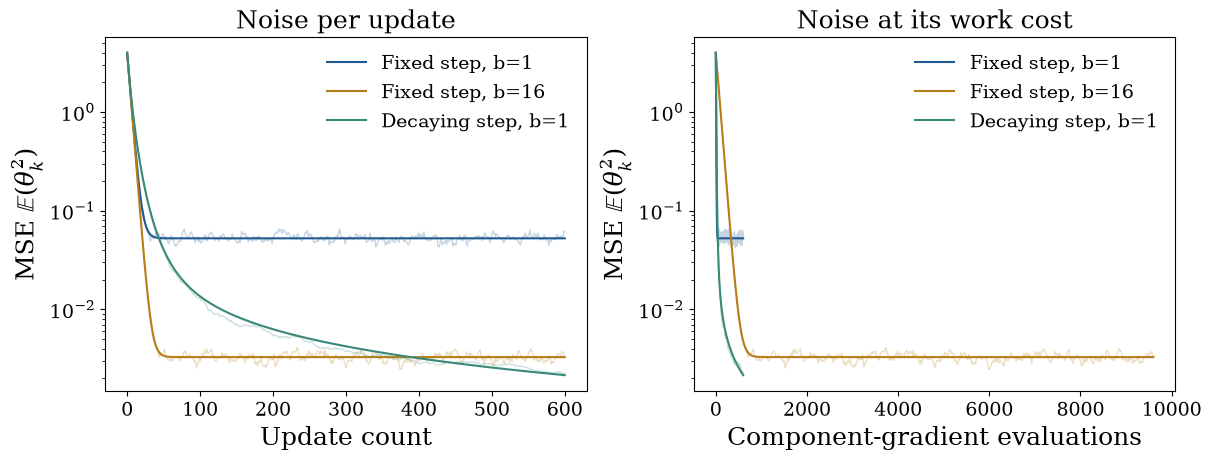

In [8]:
noise_curves=[]
for label, b, decay, color in [('Fixed step, b=1', 1, False, BLUE),
                              ('Fixed step, b=16', 16, False, GOLD),
                              ('Decaying step, b=1', 1, True, GREEN)]:
    u = qp.IIDStdUniform(1, seed=SEED+100+b+int(decay)).gen_samples(
        NOISE_STEPS*NOISE_REPEATS*b).reshape(NOISE_STEPS, NOISE_REPEATS, b)
    means = (2*(u >= .5)-1).mean(axis=2)
    theta = np.full(NOISE_REPEATS, 2.0)
    exact, measured = [4.0], [4.0]
    for k in range(NOISE_STEPS):
        eta = .1/(1+k/20) if decay else .1
        theta = (1-eta)*theta + eta*means[k]
        exact.append((1-eta)**2*exact[-1]+eta**2/b)
        measured.append(np.mean(theta**2))
    if not decay:
        powers = (1-.1)**(2*np.arange(NOISE_STEPS+1))
        closed_form = 4*powers + .1/(b*1.9)*(1-powers)
        assert np.allclose(exact, closed_form), 'Moment recurrence and geometric-series solution disagree'
    noise_curves.append((label,b,np.array(exact),np.array(measured),color))
    print(f'{label}: final exact MSE {exact[-1]:.6g}, simulated MSE {measured[-1]:.6g}'
          + (f', limiting MSE {.1/(b*1.9):.6g}' if not decay else ''))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for label, b, exact, measured, color in noise_curves:
    for ax, abscissa in zip(axes, [np.arange(NOISE_STEPS+1), b*np.arange(NOISE_STEPS+1)]):
        ax.semilogy(abscissa, exact, color=color, label=label)
        ax.semilogy(abscissa, measured, color=color, alpha=.25, linewidth=1)
axes[0].set(xlabel='Update count', ylabel=r'MSE $\mathbb{E}(\theta_k^2)$', title='Noise per update')
axes[1].set(xlabel='Component-gradient evaluations', ylabel=r'MSE $\mathbb{E}(\theta_k^2)$', title='Noise at its work cost')
for ax in axes: ax.legend(frameon=False)
plt.show()

## 5. Logistic regression: large data need not mean high dimension

Each observation is $(\boldsymbol x_i,y_i)$ with $\boldsymbol x_i\in\mathbb R^m$ and $y_i\in\{0,1\}$. Coordinate 1 is an intercept. The remaining coordinates are independent standard normals. With known generating vector $\boldsymbol\beta$, draw
\begin{gather*}
y_i=\boldsymbol1\{U_i<p_i(\boldsymbol\beta)\},\qquad
p_i(\boldsymbol\theta)=\frac{1}{1+\exp(-\boldsymbol x_i^\top\boldsymbol\theta)},\\
\operatorname{loss}_i(\boldsymbol\theta)
=\log(1+\exp(\boldsymbol x_i^\top\boldsymbol\theta))-y_i\boldsymbol x_i^\top\boldsymbol\theta
+\frac\lambda2\|\boldsymbol\theta\|^2,\\
\nabla\operatorname{loss}_i(\boldsymbol\theta)
=(p_i(\boldsymbol\theta)-y_i)\boldsymbol x_i+\lambda\boldsymbol\theta.
\end{gather*}

The full loss is the **average** of these components. We regularize every coefficient, including the intercept, so $\lambda>0$ makes this empirical objective strongly convex. The penalty is included once in each component gradient and therefore once in its average; it must not be divided by the batch size a second time.

Unlike linear least squares, this Hessian changes with the current parameters:
\begin{gather*}
H(\boldsymbol\theta)=\frac1N\sum_{i=0}^{N-1}
p_i(\boldsymbol\theta)[1-p_i(\boldsymbol\theta)]\boldsymbol x_i\boldsymbol x_i^\top+\lambda I.
\end{gather*}
A single precomputed $X^\top X$ does not determine those varying weights. Nevertheless, with $m=2$ the full gradient and the three independent Hessian entries can still be accumulated together in one $O(N)$ pass, followed by a tiny solve. **Huge $N$ does not imply that Newton is impractical when $m$ is small.** Large $N$ raises data-access cost; large $m$ raises dense-curvature storage and solve cost. The measured first-order comparison in Part 6 is not an automatic recommendation to use SGD, and the L-BFGS reference below is not a timed competitor run.

`PARAMETER_DIM` controls $m$, `N` controls data size, and `DIAGNOSTIC_SIZE` controls diagnostic subset size $s$. The known generating vector is **not** the empirical minimizer. A tightly solved L-BFGS reference supplies the empirical target loss. Reference solving and data generation are reported separately and are not competitor runs.

Name the random object whose dimension is being counted. Generating **one synthetic observation** uses $m-1$ uniform coordinates for Gaussian features and one for its binary label; the intercept is deterministic. That observation-generation stage is separate from SGD on the resulting fixed dataset. One **mini-batch-gradient draw** samples the length-$b$ index vector $(I_0,\ldots,I_{b-1})$ from that fixed dataset, requiring $b$ uniform coordinates. Therefore its input dimension is **$d=b$**, while its output gradient has $m$ coordinates. Single-observation SGD has $b=1$, hence $d=1$.

| Symbol | Role in the default logistic experiment |
|---|---|
| $m=20$ | Model parameters, including the intercept; also gradient output dimension |
| $N=16{,}384$ | Fixed observed data rows after generation |
| $b=64$ | IID observation indices averaged per mini-batch update |
| $s=1{,}024$ | Fixed randomly selected diagnostic observations; reused at every checkpoint |
| $d=b=64$ | Random-input dimension of one default mini-batch-gradient draw; $d=1$ for single-observation SGD |

Throughout this comparison, the sampling unit is **one gradient estimate**. The scalar IID stream in the code is grouped into length-$b$ index vectors; grouping does not change the IID law or any result. Keep the roles distinct: $d=b$ random-input coordinates for one batch draw, $m$ gradient/parameter coordinates, and $N$ fixed observations. The categorical index map is a step function in each input coordinate. Dimension alone does not predict QMC gains; a QMC or reshuffling replacement requires a fresh analysis of dependence and error rather than an unchanged IID $\sigma_k^2/b$ identity.

In [9]:
t0 = time.perf_counter()
X = np.column_stack([np.ones(N), qp.Gaussian(qp.IIDStdUniform(PARAMETER_DIM-1, seed=SEED+200)).gen_samples(N)])
beta = np.r_[.3, np.linspace(-1, 1, PARAMETER_DIM-1)/np.sqrt(PARAMETER_DIM-1)*2]
y = (qp.IIDStdUniform(1, seed=SEED+201).gen_samples(N).ravel() < expit(X@beta)).astype(float)
data_seconds = time.perf_counter()-t0

def logistic_loss(theta):
    z = X@theta
    return np.mean(np.logaddexp(0, z)-y*z) + REGULARIZATION*(theta@theta)/2

def logistic_gradient(theta, indices=None):
    xb, yb = (X, y) if indices is None else (X[indices], y[indices])
    return xb.T@(expit(xb@theta)-yb)/len(yb) + REGULARIZATION*theta

# Independent finite differences and explicit component averaging check the model.
probe = np.linspace(-.1, .1, PARAMETER_DIM)
h = 1e-5
numeric = np.array([(logistic_loss(probe+h*np.eye(PARAMETER_DIM)[j])-logistic_loss(probe-h*np.eye(PARAMETER_DIM)[j]))/(2*h)
                    for j in range(PARAMETER_DIM)])
assert np.allclose(logistic_gradient(probe), numeric, atol=1e-8, rtol=1e-5)
all_components = (expit(X@probe)-y)[:,None]*X + REGULARIZATION*probe
assert np.allclose(all_components.mean(axis=0), logistic_gradient(probe))
# logaddexp and expit also work for extreme logits without clipping the objective.
assert np.isfinite(logistic_loss(np.full(PARAMETER_DIM, 1000.)))

# Hessian <= X.T@X/(4N) + lambda I, uniformly in theta; charge this setup.
t0 = time.perf_counter()
L_bound = np.linalg.eigvalsh(X.T@X/(4*N))[-1]+REGULARIZATION
curvature_seconds = time.perf_counter()-t0

# Select s distinct rows once, using a separate IID stream; keep them fixed.
t0 = time.perf_counter()
diagnostic_sampler = qp.IIDStdUniform(1, seed=SEED+202)
diagnostic_indices, diagnostic_seen = [], set()
while len(diagnostic_indices) < DIAGNOSTIC_SIZE:
    for u in diagnostic_sampler.gen_samples(min(4096, DIAGNOSTIC_SIZE-len(diagnostic_indices))).ravel():
        index = min(int(N*u), N-1)
        if index not in diagnostic_seen:
            diagnostic_indices.append(index)
            diagnostic_seen.add(index)
diagnostic_indices = np.array(diagnostic_indices, dtype=int)
diagnostic_setup_seconds = time.perf_counter()-t0
assert len(np.unique(diagnostic_indices)) == DIAGNOSTIC_SIZE

# This is a loss diagnostic on s rows, not a mini-batch gradient or a full loss.
def diagnostic_loss(theta):
    xb, yb = X[diagnostic_indices], y[diagnostic_indices]
    z = xb@theta
    return np.mean(np.logaddexp(0,z)-yb*z) + REGULARIZATION*(theta@theta)/2

# Known lambda-strong convexity calibrates the full-gradient tolerance.
gradient_tolerance = np.sqrt(2*REGULARIZATION*LOSS_GAP_TARGET)
t0 = time.perf_counter()
reference = minimize(logistic_loss, np.zeros(PARAMETER_DIM), jac=logistic_gradient, method='L-BFGS-B',
                     options={'gtol': 1e-11, 'ftol': 1e-15, 'maxiter': 2000})
reference_seconds = time.perf_counter()-t0
assert reference.success, reference.message
assert np.linalg.norm(logistic_gradient(reference.x), np.inf) < 1e-7
reference_loss = reference.fun
print(f'N={N:,}, m={PARAMETER_DIM}; data matrix {X.nbytes/2**20:.2f} MiB; labels mean {y.mean():.3f}')
print(f'Data generation {data_seconds:.3f} s; curvature setup {curvature_seconds:.3f} s; '
      f'diagnostic subset setup {diagnostic_setup_seconds:.3f} s; reference solve {reference_seconds:.3f} s')
print(f'Diagnostic subset s={DIAGNOSTIC_SIZE:,}; update batch b={BATCH_SIZE}; parameters m={PARAMETER_DIM}')
print(f'Full-gradient norm target tau={gradient_tolerance:.6g} for loss-gap target epsilon={LOSS_GAP_TARGET:g}')
print(f'Reference loss {reference_loss:.12f}; gradient infinity norm '
      f'{np.linalg.norm(logistic_gradient(reference.x),np.inf):.3g}')
print(f'Full-GD learning rate 1/L = {1/L_bound:.4g}, using a uniform Hessian bound')

N=16,384, m=20; data matrix 2.50 MiB; labels mean 0.555
Data generation 0.007 s; curvature setup 0.000 s; diagnostic subset setup 0.000 s; reference solve 0.004 s
Diagnostic subset s=1,024; update batch b=64; parameters m=20
Full-gradient norm target tau=0.002 for loss-gap target epsilon=0.0001
Reference loss 0.570684340602; gradient infinity norm 1.22e-10
Full-GD learning rate 1/L = 3.504, using a uniform Hessian bound


## 6. Compare gradient work and elapsed time separately

Notation reminder: $\boldsymbol g_k=\nabla\operatorname{Loss}(\boldsymbol\theta_k)$ is the full gradient; $\boldsymbol G_k$ is its sampled approximation used for an SGD update. $m$ counts parameters, $b$ update observations, $s$ diagnostic observations, and $N$ all data rows.

The numerical reference minimizer and loss are **benchmark targets**, not inputs to the parameter updates. Those updates use the data, current iterate, selected batch, and declared learning rate.

Every run uses exactly `N * BUDGET_PASSES` component-gradient contributions. Dividing this work by $N$ gives **equivalent data passes**. For SGD these are draws with replacement, not epochs visiting every observation exactly once. The initial iterate is recorded; logarithmic plots show the positive-work/time checkpoints. The loss-gap plotting floor is $10^{-12}$; the tables retain the computed gaps.

| Implemented method | Observations used in one update | Actual learning rate |
|---|---:|---|
| Full GD | All $N$ rows, once each | $1/L_{\mathrm{bound}}$ |
| Single-observation SGD | $b=1$, with replacement | $0.3/[1+w_k/(0.25N)]$ |
| Mini-batch, fixed | $b=64$ by default, with replacement | $0.3$ |
| Mini-batch, decay | $b=64$ by default, with replacement | $0.3/[1+w_k/(0.25N)]$ |

Here $w_k$ is component work **before** update $k$, so decay is tied to data access rather than update count. Every stochastic run starts at $0.3$; at the nominal work boundary $w=12N$, the formula gives $0.3/49\approx0.006122$. The final applied step is slightly larger because its work count excludes the final batch. These are declared comparison settings, not the output of the trial-and-adjust recipe above: the code runs no pilot search and does not change a rate in response to observed loss. The code chooses `eta` from prior work before drawing the next update batch.

Each stochastic run samples fresh IID indices. Index generation, array selection, arithmetic, snapshot storage, and update bookkeeping are inside its optimization timer. An index buffer generates 4096 uniform draws at a time, including unused draws in the final buffer. No full loss is evaluated inside these timers. We save at most about 45 parameter snapshots and evaluate losses afterward, charging their times separately: a fixed $s$-row diagnostic loss for practical progress monitoring, and the full empirical loss for retrospective benchmark gaps. The diagnostic subset is selected once independently of the update streams and reused across methods and checkpoints. It estimates training loss, not held-out prediction error or an optimality gap. Its cost is $O(sm)$ per check; full loss costs $O(Nm)$. Typically $b\ll s\ll N$. Repeated tuning against a fixed subset can overfit it, so a plateau is not an accuracy certificate. Otherwise frequent $N$-row loss checks could erase the benefit we are trying to measure.

Each method gets a short untimed warmup, then `TIMING_REPEATS` complete measured runs. Timing curves show medians at common work checkpoints; bands show the observed range, not confidence intervals. Data/reference setup is shared and excluded from the optimization timer. Curves are machine-specific: vectorized full gradients may beat Python-level SGD even when the latter uses fewer rows early.

### Curvature scale and setup cost

The full-GD bound is $L=\lambda_{\max}(X^\top X/(4N))+\lambda$, since logistic curvature weights are at most $1/4$. The code uses $\lambda=0.02$, $N=16{,}384$, and $m=20$ by default. Its saved output gives $1/L_{\mathrm{bound}}\approx3.504$, or $L_{\mathrm{bound}}\approx0.2854$. The SGD initial/fixed rate $0.3$ is smaller than that curvature scale, but its strict expected-descent condition still depends on signal and noise. Forming $X^\top X$ to obtain this bound costs $O(Nm^2)$ in the dense model; it happens once outside the optimization timers and is reported separately as curvature setup time. A complete end-to-end comparison must charge that setup, along with any rate-tuning pilot. It is uniform over parameter values and uses the **fixed data**, not the mini-batch variance. A larger valid bound is conservative. The SGD rates in the table do not use the noise diagnostic or minimize the expected-descent bound. Equal gradient-row budgets, different update counts, different step schedules, and vectorization all influence the comparison; it does not isolate sampling as the only difference. Read the actual saved result before concluding which method reaches useful accuracy fastest on this machine.

### Stopping evidence versus a budget stop

Every optimizer here **runs to its component-work budget**. The stored-loss plots are retrospective; there is no online rate tuning or loss-based early exit. A first recorded target crossing below is a benchmark observation, not when the optimizer stopped.

At each run's endpoint, separately compute the exact full gradient $\boldsymbol g=\nabla\operatorname{Loss}(\boldsymbol\theta)$ and its Euclidean norm. For this fully regularized logistic model,
\begin{gather*}
\operatorname{Loss}(\boldsymbol\theta)-\operatorname{Loss}(\boldsymbol\theta_*)
\leq \frac{\|\boldsymbol g\|^2}{2\lambda},\qquad
\tau=\sqrt{2\lambda\varepsilon}.
\end{gather*}
Thus $\|\boldsymbol g\|\leq\tau$ certifies a loss gap at most the requested $\varepsilon$, up to numerical error. This check uses $N$ component gradients and has its own timer; it is extra work beyond the equal optimizer budgets. It uses known strong convexity and needs no numerical reference minimum. An ordinary noisy $\boldsymbol G_k$ need not vanish at the minimizer; using it for a stopping decision would require a justified uncertainty assessment. Small updates or a diagnostic-loss plateau alone do not certify this target.


In [10]:
class IIDIndices:
    def __init__(self, seed):
        self.sampler = qp.IIDStdUniform(1, seed=seed)
        self.buffer = np.empty(0, dtype=int)
        self.cursor = 0
    def take(self, size):
        if self.cursor+size > len(self.buffer):
            self.buffer = (N*self.sampler.gen_samples(max(4096,size)).ravel()).astype(int)
            self.cursor = 0
        result = self.buffer[self.cursor:self.cursor+size]
        self.cursor += size
        return result

METHODS = [
    ('Full GD', None, False, BLUE),
    ('SGD, b=1, decay', 1, True, RED),
    (f'Mini-batch b={BATCH_SIZE}, fixed', BATCH_SIZE, False, GOLD),
    (f'Mini-batch b={BATCH_SIZE}, decay', BATCH_SIZE, True, GREEN),
]

def optimize(method, seed, budget):
    name, b, decay, color = method
    size = N if b is None else b
    updates = int(np.ceil(budget/size))
    checkpoints = set(np.unique(np.geomspace(1, updates, min(45,updates)).astype(int)))
    theta = np.zeros(PARAMETER_DIM)
    works, seconds, snapshots = [0], [0.0], [theta.copy()]
    started = time.perf_counter()
    sampler = IIDIndices(seed) if b is not None else None
    work = 0
    for k in range(1, updates+1):
        used = min(size, budget-work)
        if b is None:
            # Full runs have an integer number of complete N-row gradients.
            assert used == N
            eta = 1/L_bound
            g_k = logistic_gradient(theta)
            direction = g_k
        else:
            eta = .3/(1+work/(.25*N)) if decay else .3
            G_k = logistic_gradient(theta, sampler.take(used))
            direction = G_k
        theta -= eta*direction
        work += used
        if k in checkpoints:
            works.append(work)
            snapshots.append(theta.copy())
            seconds.append(time.perf_counter()-started)
    elapsed = time.perf_counter()-started
    # Stop the timer before evaluating any full-loss diagnostics.
    seconds[-1] = elapsed
    diagnostic_start = time.perf_counter()
    diagnostic_losses = np.array([diagnostic_loss(x) for x in snapshots])
    diagnostic_seconds = time.perf_counter()-diagnostic_start
    full_loss_start = time.perf_counter()
    losses = np.array([logistic_loss(x) for x in snapshots])
    full_loss_seconds = time.perf_counter()-full_loss_start
    gradient_check_start = time.perf_counter()
    final_g = logistic_gradient(theta)
    final_gradient_norm = np.linalg.norm(final_g)
    gap_upper_bound = final_gradient_norm**2/(2*REGULARIZATION)
    gradient_check_seconds = time.perf_counter()-gradient_check_start
    assert losses[-1]-reference_loss <= gap_upper_bound+1e-10
    assert np.all(np.isfinite(diagnostic_losses))
    assert work == budget and np.all(np.isfinite(losses))
    assert np.all(losses >= reference_loss-1e-10), 'Reference loss is not a valid numerical lower target'
    return dict(work=np.array(works), seconds=np.array(seconds), loss=losses,
                gap=np.maximum(losses-reference_loss,0), elapsed=elapsed,
                diagnostics=diagnostic_seconds, diagnostic_loss=diagnostic_losses,
                full_loss_seconds=full_loss_seconds, gradient_check_seconds=gradient_check_seconds,
                final_gradient_norm=final_gradient_norm, gap_upper_bound=gap_upper_bound,
                gradient_target_met=bool(final_gradient_norm <= gradient_tolerance),
                stop_reason='component-work budget', updates=updates)

# Warm up exactly the same gradient/selection paths; use independent seeds for measured runs.
for method in METHODS:
    optimize(method, SEED+300, N if method[1] is None else min(N,20*method[1]))
results={}
for j, method in enumerate(METHODS):
    results[method[0]] = [optimize(method, SEED+400+100*j+r, N*BUDGET_PASSES)
                          for r in range(TIMING_REPEATS)]
print('All runs stopped at the same component-gradient budget; sampled/full losses and endpoint gradient checks were evaluated afterward.')

All runs stopped at the same component-gradient budget; sampled/full losses and endpoint gradient checks were evaluated afterward.


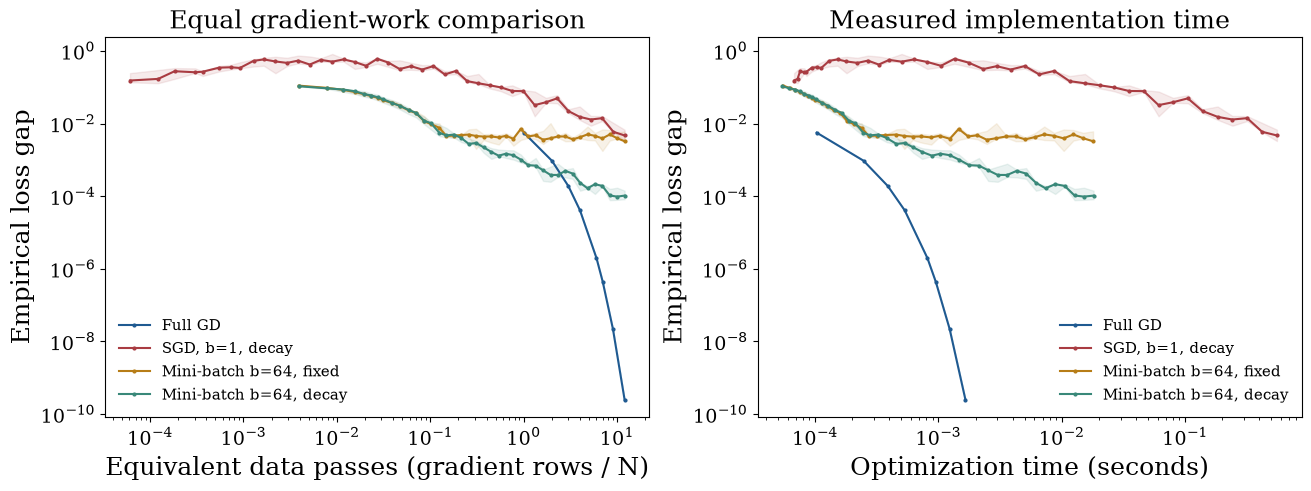

,Method,Updates,Gradient rows,Optimization seconds (median),s-row monitoring seconds (median),Full-loss benchmark seconds (median),Endpoint gradient-check seconds (median),Final loss gap (median)
0,Full GD,12,196608,0.00165729,0.000236875,0.00184129,0.000138542,2.48157e-10
1,"SGD, b=1, decay",196608,196608,0.555306,0.00130683,0.0098265,0.00015525,0.00469175
2,"Mini-batch b=64, fixed",3072,196608,0.0179349,0.00113512,0.00941275,0.000147333,0.00324939
3,"Mini-batch b=64, decay",3072,196608,0.0181192,0.00105263,0.008793,0.000152208,0.000103668


In this run, Full GD used the least optimization time: 0.001657 s, with final loss gap 2.48e-10. Read time and accuracy together.


,Method,Requested loss gap,Runs reaching target,First recorded seconds (median of successes)
0,Full GD,0.01,3/3,0.000103125
1,Full GD,0.0001,3/3,0.000533833
2,Full GD,1e-06,3/3,0.000952667
3,"SGD, b=1, decay",0.01,3/3,0.421052
4,"SGD, b=1, decay",0.0001,0/3,NaN
5,"SGD, b=1, decay",1e-06,0/3,NaN
6,"Mini-batch b=64, fixed",0.01,3/3,0.000205333
7,"Mini-batch b=64, fixed",0.0001,0/3,NaN
8,"Mini-batch b=64, fixed",1e-06,0/3,NaN
9,"Mini-batch b=64, decay",0.01,3/3,0.000237417


NaN means no recorded attainment within the budget; success-only medians are not comparable without reading the success count. Checkpoint spacing limits the time resolution.


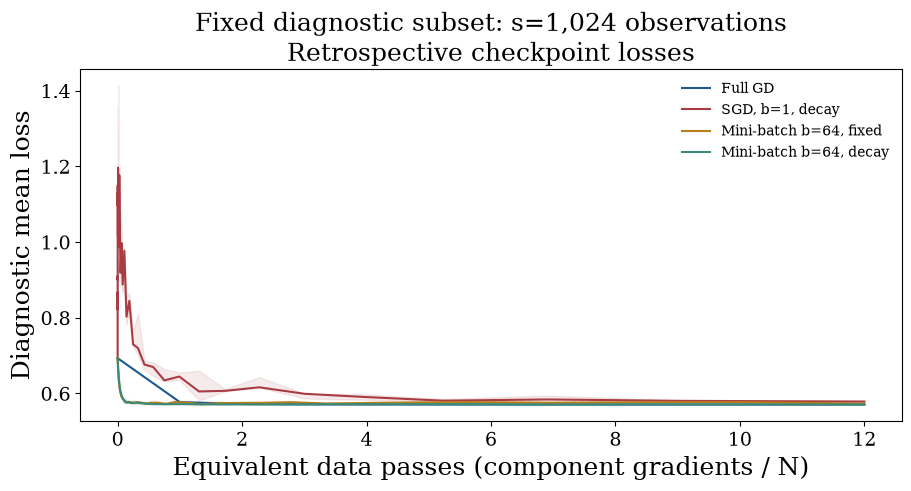

,Method,Run,Stop reason,Full-gradient norm,Tolerance tau,Certified loss-gap upper bound,Gradient target met
0,Full GD,1,component-work budget,8.63543e-06,0.002,1.86426e-09,True
1,Full GD,2,component-work budget,8.63543e-06,0.002,1.86426e-09,True
2,Full GD,3,component-work budget,8.63543e-06,0.002,1.86426e-09,True
3,"SGD, b=1, decay",1,component-work budget,0.0441013,0.002,0.0486232,False
4,"SGD, b=1, decay",2,component-work budget,0.0379485,0.002,0.0360021,False
5,"SGD, b=1, decay",3,component-work budget,0.0543026,0.002,0.0737192,False
6,"Mini-batch b=64, fixed",1,component-work budget,0.0373948,0.002,0.0349593,False
7,"Mini-batch b=64, fixed",2,component-work budget,0.0517068,0.002,0.0668399,False
8,"Mini-batch b=64, fixed",3,component-work budget,0.0368031,0.002,0.0338617,False
9,"Mini-batch b=64, decay",1,component-work budget,0.0060207,0.002,0.000906219,False


All runs stopped at the budget. The final check reports whether the accuracy target was also met; a failed check does not establish that the loss gap exceeds the target.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
rows=[]
for name, b, decay, color in METHODS:
    runs = results[name]
    gaps = np.array([r['gap'] for r in runs])
    median_gap = np.maximum(np.median(gaps,axis=0), 1e-12)
    med_seconds = np.median([r['seconds'] for r in runs],axis=0)
    work = runs[0]['work']/N
    for ax, x in [(axes[0],work), (axes[1],med_seconds)]:
        ax.plot(x[1:], median_gap[1:], color=color, marker='.', markersize=4, label=name)
        ax.fill_between(x[1:], np.maximum(gaps.min(axis=0)[1:],1e-12),
                         np.maximum(gaps.max(axis=0)[1:],1e-12), color=color, alpha=.1)
    rows.append([name, runs[0]['updates'], int(runs[0]['work'][-1]),
                 np.median([r['elapsed'] for r in runs]),
                 np.median([r['diagnostics'] for r in runs]),
                 np.median([r['full_loss_seconds'] for r in runs]),
                 np.median([r['gradient_check_seconds'] for r in runs]), np.median(gaps[:,-1])])
axes[0].set(xlabel='Equivalent data passes (gradient rows / N)', title='Equal gradient-work comparison')
axes[1].set(xlabel='Optimization time (seconds)', title='Measured implementation time')
for ax in axes:
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_ylabel('Empirical loss gap')
    ax.legend(frameon=False,fontsize=11)
plt.show()
summary=pd.DataFrame(rows,columns=['Method','Updates','Gradient rows','Optimization seconds (median)',
                                  's-row monitoring seconds (median)','Full-loss benchmark seconds (median)',
                                  'Endpoint gradient-check seconds (median)','Final loss gap (median)'])
display(summary)
best = summary.loc[summary['Optimization seconds (median)'].idxmin()]
print(f"In this run, {best['Method']} used the least optimization time: "
      f"{best['Optimization seconds (median)']:.4g} s, with final loss gap "
      f"{best['Final loss gap (median)']:.3g}. Read time and accuracy together.")

# First recorded attainment, not an interpolated or assumed crossing.
attainments=[]
for name, _, _, _ in METHODS:
    for target in [1e-2,1e-4,1e-6]:
        hits=[np.flatnonzero(r['gap']<=target) for r in results[name]]
        times=[r['seconds'][h[0]] for r,h in zip(results[name],hits) if len(h)]
        attainments.append([name,target,f'{len(times)}/{TIMING_REPEATS}',
                             np.median(times) if times else np.nan])
display(pd.DataFrame(attainments,columns=['Method','Requested loss gap','Runs reaching target',
                                          'First recorded seconds (median of successes)']))
print('NaN means no recorded attainment within the budget; success-only medians are not comparable '
      'without reading the success count. Checkpoint spacing limits the time resolution.')

# Same s observations for every method and checkpoint; no reference minimum needed.
fig, ax = plt.subplots(figsize=(9,4.8), constrained_layout=True)
for name, b, decay, color in METHODS:
    runs = results[name]
    subset_losses = np.array([r['diagnostic_loss'] for r in runs])
    work = runs[0]['work']/N
    ax.plot(work, np.median(subset_losses,axis=0), color=color, label=name)
    ax.fill_between(work, subset_losses.min(axis=0), subset_losses.max(axis=0),
                    color=color, alpha=.1)
ax.set(xlabel='Equivalent data passes (component gradients / N)',
       ylabel='Diagnostic mean loss',
       title=f'Fixed diagnostic subset: s={DIAGNOSTIC_SIZE:,} observations\nRetrospective checkpoint losses')
ax.legend(frameon=False,fontsize=10)
plt.show()

endpoint_rows = []
for name, _, _, _ in METHODS:
    for repeat, run in enumerate(results[name],1):
        endpoint_rows.append([name,repeat,run['stop_reason'],run['final_gradient_norm'],
                              gradient_tolerance,run['gap_upper_bound'],run['gradient_target_met']])
display(pd.DataFrame(endpoint_rows,columns=[
    'Method','Run','Stop reason','Full-gradient norm','Tolerance tau',
    'Certified loss-gap upper bound','Gradient target met']))
print('All runs stopped at the budget. The final check reports whether the accuracy target was also met; '
      'a failed check does not establish that the loss gap exceeds the target.')


## 7. What these experiments establish

The Rosenbrock experiment isolates **geometry**. Its narrow valley remains difficult for GD with a line search. BFGS uses curvature information to improve its route. A high parameter count would not remove that issue.

The quadratic experiments isolate **sampling noise** and distinguish exact-reference measurements from a single-batch noise estimate. Mini-batch gradient MSE decreases as $1/b$ for fresh independent component draws. With nonvanishing component noise, a fixed step can leave a noise floor. A smaller or decreasing step improves fine accuracy at the cost of slower progress.

The logistic experiment compares **data-access cost, declared learning rates, and implementation time**. Compare the left panel before the first complete data pass, then near the final requested loss gap. Read the measured time panel separately: row counts omit Python overhead, memory traffic, vectorization, and library threading. No method is declared universally faster, and this CPU implementation predicts no GPU speedup. Full-gradient and curvature-aware methods can be excellent when full gradients are affordable or high precision is needed.

A dense Hessian uses $O(m^2)$ storage, with an $O(m^3)$ naive dense solve. **L-BFGS**, sparse structure, and Hessian-vector methods can avoid those costs. Reverse-mode automatic differentiation, also called **adjoint-mode differentiation** or a **discrete adjoint method**, can compute the whole gradient at cost comparable to a few loss evaluations; large $m$ does not imply $m$ finite-difference evaluations. In neural networks this is called **backpropagation**. Momentum and Adam are additional ways to modify first-order updates, not general cures for conditioning or nonconvexity. Changing curvature and nonconvexity remain distinct: the logistic objective here is nonquadratic but strongly convex.

Optimization loss and prediction error are different. This notebook measures an empirical optimization objective; it does not test generalization or prove a global-minimum result for neural networks.

The logistic monitoring plot reuses the same $s$ diagnostic observations. Full-loss gaps and first target attainments use an expensive numerical reference for assessment only. Every run stops at its budget; the separate final full-gradient check provides a strong-convexity loss-gap bound. The update, sampled-monitoring, full-benchmark and final-check times are reported separately.

### Try next

1. Set `PARAMETER_DIM=2` and increase `N`. Does the data-access advantage need high dimension?
2. Hold `N` fixed and increase `PARAMETER_DIM`. Which storage and arithmetic costs increase? Does this necessarily worsen conditioning?
3. Change `BATCH_SIZE` and the declared step sizes. Compare early progress with attainment of a gap of $10^{-6}$. Changing only the plotted update count is not an equal-work comparison.
4. In the scalar recurrence, predict the noise floor for $b=4$ and $\eta=0.05$ before running it.

### References

- [Bottou, Curtis, and Nocedal (2018), Optimization Methods for Large-Scale Machine Learning](https://arxiv.org/abs/1606.04838), especially §§3–7
- [SciPy optimization tutorial](https://docs.scipy.org/doc/scipy/tutorial/optimize.html), Rosenbrock, BFGS, Newton and trust-region examples
- [Levitt, The adjoint trick](https://www.imo.universite-paris-saclay.fr/~antoine.levitt/blog/adjoint/), reverse-mode AD, adjoint methods, and backpropagation

In [12]:
elapsed = time.perf_counter() - NOTEBOOK_START_TIME
minutes, seconds = divmod(elapsed, 60)
print(f'Total execution time for this notebook is {int(minutes)} min {seconds:.1f} sec.')

Total execution time for this notebook is 0 min 5.0 sec.
